<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/01_tabular/06_recommender_app_movielens.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎬 Application · Recommender systems: The million-dollar movie night

**October 2, 2006.** Netflix announces a prize: **$1,000,000** to the first team that improves its movie recommendation
algorithm (*Cinematch*) by 10% in RMSE. They release 100 million ratings from 480 000 customers. More than 40 000 teams
from 186 countries join. After three years, the team *BellKor's Pragmatic Chaos* wins… **20 minutes** before the
runner-up submits an equally good solution.

Two ideas from that competition changed the industry: **matrix factorisation** (popularised by Simon Funk's blog post
during the contest) and **blending** many models. Today every app recommends something: Netflix, YouTube, Spotify,
Jumia, TikTok…

**Mission:** predict how a user would rate a movie they haven't seen, then recommend movies to **you**.
Data: **MovieLens** (GroupLens lab, University of Minnesota, since 1997), 100 000 ratings by 610 users.

| You will learn | Concept |
|---|---|
| The user × item matrix and why it's 98% empty | sparsity |
| Baselines that are surprisingly strong | global mean, user & item biases |
| Collaborative filtering | item-item similarity |
| Matrix factorisation | latent factors, trained with gradient descent |
| Ranking metrics | precision@k |

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

quest("The million-dollar movie night", chapter="Track 1 · Tabular · Recommender systems (bonus)", xp=250)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · The million-dollar movie night
   Track 1 · Tabular · Recommender systems (bonus)
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Load 📥

In [3]:
folder = download_and_extract("https://files.grouplens.org/datasets/movielens/ml-latest-small.zip",
                              "movielens", marker="ml-latest-small") / "ml-latest-small"
ratings = pd.read_csv(folder / "ratings.csv")
movies = pd.read_csv(folder / "movies.csv")
print(f"{len(ratings):,} ratings · {ratings.userId.nunique()} users · {ratings.movieId.nunique():,} movies")
ratings.merge(movies, on="movieId").sample(5, random_state=SEED)

100,836 ratings · 610 users · 9,724 movies


,userId,movieId,rating,timestamp,title,genres
67037,432,77866,4.5,1335139641,Robin Hood (2010),Action|Adventure|Drama|Romance|War
42175,288,474,3.0,978465565,In the Line of Fire (1993),Action|Thriller
93850,599,4351,3.0,1498524542,Point Break (1991),Action|Crime|Thriller
6187,42,2987,4.0,996262677,Who Framed Roger Rabbit? (1988),Adventure|Animation|Children|Comedy|Crime|Fant...
12229,75,1610,4.0,1158989841,"Hunt for Red October, The (1990)",Action|Adventure|Thriller


## 2. EDA: a very empty matrix 🕳️

The user × movie matrix has 5,931,640 cells, only 1.7% are filled.


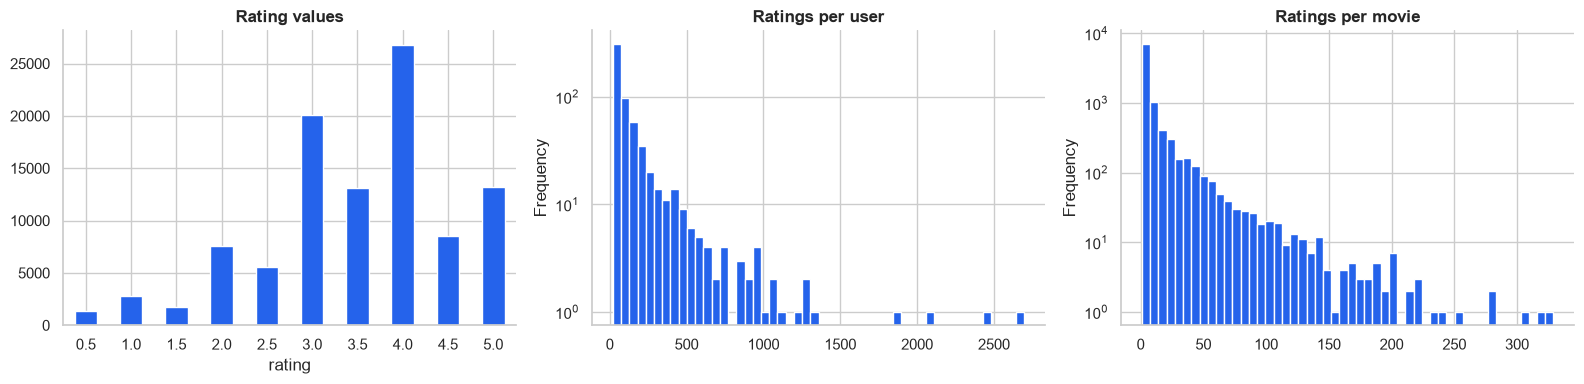

In [4]:
n_users, n_items = ratings.userId.nunique(), ratings.movieId.nunique()
density = len(ratings) / (n_users * n_items)
print(f"The user × movie matrix has {n_users * n_items:,} cells, only {density:.1%} are filled.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ratings["rating"].value_counts().sort_index().plot.bar(ax=axes[0], title="Rating values", rot=0)
ratings.groupby("userId").size().plot.hist(bins=50, ax=axes[1], logy=True, title="Ratings per user")
ratings.groupby("movieId").size().plot.hist(bins=50, ax=axes[2], logy=True, title="Ratings per movie")
plt.tight_layout(); plt.show()

A **long tail**: a few blockbusters get hundreds of ratings, most movies only a handful. Recommending well in the tail
is the hard (and valuable) part.

## 3. Train / test split ✂️

For each user we hide 20% of their ratings: the model must predict them. (A stricter alternative used in production:
hide each user's most **recent** ratings, to mimic predicting the future.)

In [5]:
rng = np.random.default_rng(SEED)
is_test = ratings.groupby("userId")["rating"].transform(lambda s: rng.random(len(s)) < 0.2).astype(bool)
train, test = ratings[~is_test].copy(), ratings[is_test].copy()
test = test[test.movieId.isin(train.movieId)]          # we can't predict movies never seen in training
print(len(train), len(test))

def rmse(pred, truth):
    return float(np.sqrt(np.mean((np.asarray(pred) - np.asarray(truth)) ** 2)))

lb = Leaderboard("movielens", metric="RMSE", higher_is_better=False)

80779 19234


## 4. Baselines: biases explain a lot 🧱

- **Global mean**: predict the average rating for everything.
- **Biases**: some users are generous (*user bias*), some movies are loved by everyone (*item bias*).
  `prediction = global_mean + user_bias + item_bias`. We shrink biases toward 0 when there are few ratings
  (regularisation, `λ`): a movie rated 5★ by a single person is not a masterpiece yet.

In [6]:
mu = train.rating.mean()
lb.add("Global mean", rmse(np.full(len(test), mu), test.rating))

lam = 5.0
item_bias = train.groupby("movieId")["rating"].agg(lambda r: (r - mu).sum() / (len(r) + lam))
train["res"] = train.rating - mu - train.movieId.map(item_bias)
user_bias = train.groupby("userId")["res"].agg(lambda r: r.sum() / (len(r) + lam))

def predict_bias(df):
    return (mu + df.movieId.map(item_bias).fillna(0) + df.userId.map(user_bias).fillna(0)).clip(0.5, 5)

lb.add("Global mean + user & item biases", rmse(predict_bias(test), test.rating))

📋 Global mean: RMSE = 1.03827


📋 Global mean + user & item biases: RMSE = 0.86267  👑 new best!


That simple formula already captures a big part of what is predictable. In the Netflix Prize, biases alone were
competitive with many early submissions.

In [7]:
checkpoint("recsys/baselines", xp=40)

✅ Checkpoint · recsys/baselines (+40 XP)
   █████████░░░░░░░░░░░░░░░ 40/100 XP


## 5. Collaborative filtering: "people who liked this also liked…" 🤝

**Item-item collaborative filtering** (Amazon, 2003): two movies are similar if the same users rate them in the same
way. To predict your rating for movie *m*, look at the movies you rated that are most similar to *m*.

We build the (user × movie) matrix of rating residuals and compute cosine similarities between movies.

In [8]:
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

user_index = {u: i for i, u in enumerate(sorted(ratings.userId.unique()))}
item_index = {m: j for j, m in enumerate(sorted(train.movieId.unique()))}
u_idx = train.userId.map(user_index).to_numpy()
i_idx = train.movieId.map(item_index).to_numpy()
residual = (train.rating - predict_bias(train)).to_numpy()
R = csr_matrix((residual, (u_idx, i_idx)), shape=(len(user_index), len(item_index)))
S = cosine_similarity(R.T, dense_output=True)          # movie × movie similarity
np.fill_diagonal(S, 0)
print("Similarity matrix:", S.shape)

def predict_itemknn(df, k=30):
    preds = []
    R_csr = R.tocsr()
    for u, m, base in zip(df.userId, df.movieId, predict_bias(df)):
        row = R_csr[user_index[u]]
        rated, vals = row.indices, row.data
        sims = S[item_index[m], rated]
        top = np.argsort(-np.abs(sims))[:k]
        w = sims[top]
        preds.append(base + (w @ vals[top]) / (np.abs(w).sum() + 1e-9) if len(top) else base)
    return np.clip(preds, 0.5, 5)

lb.add("Item-item CF (k=30)", rmse(predict_itemknn(test), test.rating))

Similarity matrix: (8982, 8982)


📋 Item-item CF (k=30): RMSE = 0.84488  👑 new best!


In [9]:
title = movies.set_index("movieId")["title"]
n_ratings = train.groupby("movieId").size()
def similar_movies(name, n=8, min_ratings=20):
    """Most similar movies, among movies with enough ratings (similarities from 3 ratings are pure noise)."""
    m = movies[movies.title.str.contains(name, regex=False)].movieId.iloc[0]
    j = item_index[m]
    inv = {v: k for k, v in item_index.items()}
    sims = S[j].copy()
    sims[[n_ratings[inv[k]] < min_ratings for k in range(len(sims))]] = -np.inf
    best = np.argsort(-sims)[:n]
    return pd.DataFrame({"similar to " + title[m]: [title[inv[b]] for b in best], "cosine": S[j, best].round(2)})

similar_movies("Toy Story (1995)")

,similar to Toy Story (1995),cosine
0,Toy Story 2 (1999),0.28
1,Wallace & Gromit: The Wrong Trousers (1993),0.22
2,Toy Story 3 (2010),0.22
3,Aladdin (1992),0.20
4,"Nightmare Before Christmas, The (1993)",0.19
5,"Incredibles, The (2004)",0.18
6,Blazing Saddles (1974),0.18
7,"Good, the Bad and the Ugly, The (Buono, il bru...",0.18


## 6. Matrix factorisation: the Netflix Prize weapon 🧬

Imagine each movie described by a few hidden "taste" numbers (how much action, romance, nostalgia…) and each user by
how much they like each of those. The predicted rating is the **dot product** of the two vectors:

`rating(u, m) ≈ μ + b_u + b_m + p_u · q_m`

Nobody tells the model what the factors mean: it **learns** them from the ratings by gradient descent (Simon Funk's
"FunkSVD", 2006). Here is a from-scratch implementation in NumPy, trained with stochastic gradient descent.

In [10]:
def train_mf(train_df, n_factors=40, epochs=25, lr=0.01, reg=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    U = rng.normal(0, 0.1, (len(user_index), n_factors))
    V = rng.normal(0, 0.1, (len(item_index), n_factors))
    bu, bi = np.zeros(len(user_index)), np.zeros(len(item_index))
    u = train_df.userId.map(user_index).to_numpy(); i = train_df.movieId.map(item_index).to_numpy()
    r = train_df.rating.to_numpy()
    history = []
    for epoch in range(epochs):
        for idx in rng.permutation(len(r)):
            uu, ii = u[idx], i[idx]
            err = r[idx] - (mu + bu[uu] + bi[ii] + U[uu] @ V[ii])
            bu[uu] += lr * (err - reg * bu[uu])
            bi[ii] += lr * (err - reg * bi[ii])
            U[uu], V[ii] = U[uu] + lr * (err * V[ii] - reg * U[uu]), V[ii] + lr * (err * U[uu] - reg * V[ii])
        history.append(epoch)
    return U, V, bu, bi

def predict_mf(df, model):
    U, V, bu, bi = model
    u = df.userId.map(user_index).to_numpy(); i = df.movieId.map(item_index).to_numpy()
    return np.clip(mu + bu[u] + bi[i] + np.sum(U[u] * V[i], axis=1), 0.5, 5)

import time
t0 = time.time()
mf = train_mf(train)
print(f"Trained in {time.time() - t0:.0f}s")
lb.add("Matrix factorisation (40 factors)", rmse(predict_mf(test, mf), test.rating))

Trained in 51s
📋 Matrix factorisation (40 factors): RMSE = 0.85515


Honest result: on this small dataset (100k ratings) matrix factorisation only edges out the bias baseline, and the
item-item model does better. Latent factors need **lots** of data to shine: Netflix had 100 million ratings. But MF
and item-item make *different* mistakes, so let's blend them.

In [11]:
blend = (predict_mf(test, mf) + predict_itemknn(test)) / 2
lb.add("Blend MF + item-item 🤝", rmse(blend, test.rating))
lb.show()

📋 Blend MF + item-item 🤝: RMSE = 0.84169  👑 new best!


,,model,RMSE
rank,,,
1,🥇,Blend MF + item-item 🤝,0.84169
2,🥈,Item-item CF (k=30),0.84488
3,🥉,Matrix factorisation (40 factors),0.85515
4,,Global mean + user & item biases,0.86267
5,,Global mean,1.03827


In [12]:
checkpoint("recsys/mf", xp=60)

✅ Checkpoint · recsys/mf (+60 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ░░░░░░░░░░░░░░░░░░░░░░░░ 100/300 XP


## 7. What did the factors learn? 🔮

Project the movie vectors onto their first two principal components: movies with similar audiences end up close,
although we never told the model anything about genres.

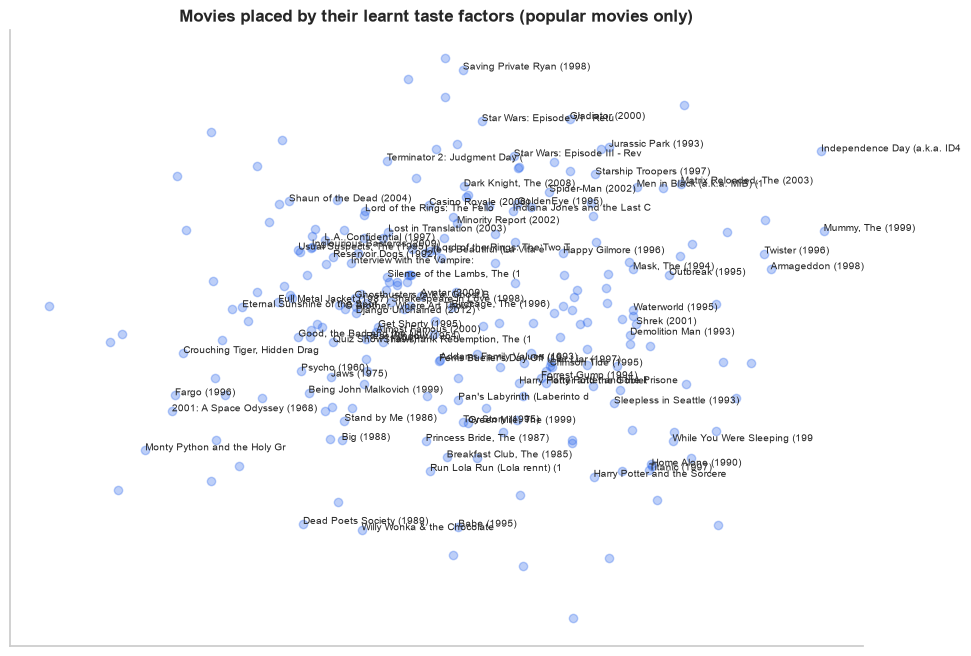

In [13]:
from sklearn.decomposition import PCA
counts = train.groupby("movieId").size()
popular = counts[counts >= 60].index
inv_item = {v: k for k, v in item_index.items()}
V2 = PCA(2, random_state=SEED).fit_transform(mf[1][[item_index[m] for m in popular]])
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(V2[:, 0], V2[:, 1], alpha=0.3)
for (x, y_), m in list(zip(V2, popular))[::3]:
    ax.text(x, y_, title[m][:28], fontsize=7)
ax.set(title="Movies placed by their learnt taste factors (popular movies only)", xticks=[], yticks=[]); plt.show()

## 8. Ranking: are the top recommendations good? 🥇

RMSE measures rating predictions, but users only see the **top of the list**. **Precision@10** = among the 10 movies
we would recommend (from the user's hidden test movies), how many did they actually love (rating ≥ 4)?

In [14]:
def precision_at_k(pred, k=10):
    df = test.assign(pred=pred)
    def per_user(g):
        top = g.nlargest(k, "pred")
        return (top.rating >= 4).mean()
    return df[df.groupby("userId").userId.transform("size") >= k].groupby("userId").apply(per_user, include_groups=False).mean()

rank_scores = pd.Series({
    "Random order": precision_at_k(rng.random(len(test))),
    "Popularity (item bias)": precision_at_k(test.movieId.map(item_bias).fillna(0).to_numpy()),
    "Matrix factorisation": precision_at_k(predict_mf(test, mf)),
    "Blend": precision_at_k(blend),
})
rank_scores.round(3).to_frame("precision@10")

,precision@10
Random order,0.540
Popularity (item bias),0.684
Matrix factorisation,0.684
Blend,0.695


Popularity is a tough baseline for ranking (people love popular movies for a reason!). The blend wins, and in a
real product personalisation also brings **diversity** and long-tail discoveries that popularity never will.

## 9. 🍿 Your personal recommendations

Rate a few movies (0.5 to 5), we fold you into the model as a new user (a few gradient steps on your vector only),
and recommend movies you haven't rated.

In [15]:
my_ratings = {                      # ✏️ edit me with your own tastes!
    "Toy Story (1995)": 5, "Lion King, The (1994)": 5, "Matrix, The (1999)": 4.5,
    "Titanic (1997)": 2, "Notebook, The (2004)": 1.5, "Star Wars: Episode IV - A New Hope (1977)": 4,
}

def recommend_for_me(my_ratings, n=10, steps=300, lr=0.05, reg=0.05):
    U, V, bu, bi = mf
    ids = [movies[movies.title == t].movieId.iloc[0] for t in my_ratings]
    idx = np.array([item_index[m] for m in ids]); r = np.array(list(my_ratings.values()), dtype=float)
    p, b = np.zeros(V.shape[1]), 0.0
    for _ in range(steps):
        err = r - (mu + b + bi[idx] + V[idx] @ p)
        b += lr * (err.mean() - reg * b)
        p += lr * (V[idx].T @ err / len(r) - reg * p)
    scores = mu + b + bi + V @ p
    scores[idx] = -np.inf                                   # don't recommend what you already rated
    enough = np.array([counts.get(inv_item[j], 0) >= 20 for j in range(len(scores))])
    scores[~enough] = -np.inf                               # skip obscure movies with < 20 ratings
    best = np.argsort(-scores)[:n]
    return pd.DataFrame({"recommended for you": [title[inv_item[j]] for j in best],
                         "predicted ★": np.clip(scores[best], 0.5, 5).round(2)})

recommend_for_me(my_ratings)

,recommended for you,predicted ★
0,"Amelie (Fabuleux destin d'Amélie Poulain, Le) ...",4.87
1,Fight Club (1999),4.84
2,Donnie Darko (2001),4.70
3,Inception (2010),4.67
4,Ex Machina (2015),4.67
5,Juno (2007),4.62
6,Reservoir Dogs (1992),4.61
7,"Dark Knight, The (2008)",4.58
8,"Graduate, The (1967)",4.58
9,"Usual Suspects, The (1995)",4.55


## 🏁 Mission accomplished

You explored a sparse matrix, built bias baselines, collaborative filtering, matrix factorisation from scratch,
blended them, and evaluated both rating accuracy and ranking quality.

### 🚀 Your turn
1. Tune `n_factors`, `reg` and `epochs` of the matrix factorisation. Plot the test RMSE vs `n_factors`.
2. Implement **user-user** collaborative filtering and compare with item-item.
3. Use the **genres** in `movies.csv` to recommend for brand-new movies with no ratings (*cold start*):
   that's **content-based** filtering.
4. Re-do the split by **time** (hide each user's last 20% ratings). Do the scores drop? Why?

In [16]:
checkpoint("recsys/complete", xp=150)
badge("Netflix Prize Challenger", "🎬")
progress()

✅ Checkpoint · recsys/complete (+150 XP)
   ██████████████████░░░░░░ 250/300 XP
╔═════════════════════════════════════════════╗
║ 🎬  BADGE UNLOCKED: Netflix Prize Challenger ║
╚═════════════════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 3
Badges: 🎬 Netflix Prize Challenger
